# LAB 09 — NER fine-tuning trên CoNLL-2003 (baseline vs pretrained Transformer, entity-level evaluation, Information Extraction)

Báo cáo chính của LAB 09. **Đã chạy, lưu kèm output**; mọi bảng/hình hiển thị inline, số trong văn bản sinh bằng f-string. Huấn luyện nặng chạy bằng `ner_core.py --run_grid` (cache vào `runs/`), notebook chỉ nạp cache (cờ `LAB09_RUN_TRAINING=1` để train lại run thiếu). Phần BIO/alignment/tokenization nằm ở `tokenizer_alignment.ipynb`.

Luồng: dữ liệu → baseline (features + Logistic Regression) → pipeline Transformer thấy rõ `tokens / input_ids / attention_mask / word_ids / labels / logits / predictions` → Exp 2 (baseline vs Transformer) → Exp 3 (entity-level) → Exp 4 (loại entity) → Exp 5 (độ dài entity) → rare entity → confusion → Exp 6 (error analysis) → context analysis → ảnh hưởng alignment → Information Extraction → learning check, reflection, AI-assisted.

In [1]:
import pandas as pd  # pandas truoc torch (Windows)
import numpy as np, json, os, random, re, collections, math, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch, transformers, sklearn
from pathlib import Path
import ner_core as nc, baseline_ner as bn, information_extraction as ie

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 90)
md = lambda s: display(Markdown(s))
RUN_TRAINING = os.environ.get("LAB09_RUN_TRAINING", "0") == "1"
RUNS = nc.RUNS_DIR
data = nc.load_conll(); test = data["test"]; gold = [r["tags"] for r in test]
SEEDS = nc.GRID_SEEDS
cfgA = {s: nc.default_config(strategy="A", seed=s) for s in SEEDS}; cfgB = nc.default_config(strategy="B", seed=42)
def get_run(cfg, save_model=False):
    name = nc.run_name(cfg)
    if not (RUNS / name / "result.json").exists():
        assert RUN_TRAINING, f"thiếu cache {name}: chạy `python ner_core.py --run_grid` hoặc đặt LAB09_RUN_TRAINING=1"
    res = nc.run_experiment(cfg, name, save_model=save_model)
    preds = json.loads((RUNS / name / "preds_test.json").read_text(encoding="utf8"))
    return res, preds
resA, predA, confA = {}, {}, {}
for s in SEEDS:
    resA[s], p = get_run(cfgA[s], save_model=(s == 42)); predA[s], confA[s] = p["pred_tags"], p["confidence"]
resB, pB = get_run(cfgB); predB = pB["pred_tags"]
if not (RUNS / "baseline" / "result.json").exists(): assert RUN_TRAINING
resBase = bn.run_baseline(); pbase = json.loads((RUNS / "baseline" / "preds_test.json").read_text(encoding="utf8")); predBase, confBase = pbase["pred_tags"], pbase["confidence"]
MAIN = 42; predT, confT = predA[MAIN], confA[MAIN]            # Transformer chính cho phân tích = seed 42, Strategy A
assert len(predT) == len(gold) == len(predBase) and all(len(a) == len(b) for a, b in zip(predT, gold))
md(f"Python `{resA[42]['hardware']['python']}`, torch `{torch.__version__}`, transformers `{transformers.__version__}`, sklearn `{sklearn.__version__}`; GPU `{resA[42]['hardware'].get('gpu')}`. "
   f"Dataset `{nc.DATASET_ID}` (parquet), model `{nc.MODEL_NAME}`; test = {len(test):,} câu, {sum(len(g) for g in gold):,} word, {len(nc.entity_set(gold)):,} entity gold.")

Python `3.14.5`, torch `2.12.0+cu126`, transformers `5.12.1`, sklearn `1.9.0`; GPU `NVIDIA GeForce RTX 3050 6GB Laptop GPU`. Dataset `eriktks/conll2003` (parquet), model `bert-base-cased`; test = 3,453 câu, 46,435 word, 5,648 entity gold.

## 0. Bảng reproducibility

Chung: encoder `bert-base-cased` (cased vì chữ hoa là tín hiệu mạnh của NER), head `Dropout(0.1) → Linear(768, 9)` tự viết (không `AutoModelForTokenClassification`), AdamW (weight_decay 0.01, không decay bias/LayerNorm), linear warmup 10% rồi decay, grad-clip 1, fp16, batch 16, `max_len=256` (không câu nào bị cắt), 3 epoch, lr 5e-5; checkpoint chọn theo **val entity-F1** (không dùng test), test đánh giá một lần cho checkpoint đó. Alignment: Strategy A (chính) / B (so sánh). Baseline: cửa sổ ±2 từ, TF-IDF sublinear, Logistic Regression (lbfgs, C chọn theo val).

In [2]:
rows = []
for s in SEEDS:
    r = resA[s]; rows.append({"run": "Transformer, Strategy A", "seed": s, "best epoch": r["best_epoch"], "train time (s)": round(r["train_time_s"]), "peak GPU mem (MB)": round(r["peak_mem_mb"]),
                              "params": f"{r['params_total']:,}", "val entity F1": round(r["val"]["entity"]["micro"]["f1"], 4), "test entity F1": round(r["test"]["entity"]["micro"]["f1"], 4)})
r = resB; rows.append({"run": "Transformer, Strategy B", "seed": 42, "best epoch": r["best_epoch"], "train time (s)": round(r["train_time_s"]), "peak GPU mem (MB)": round(r["peak_mem_mb"]),
                       "params": f"{r['params_total']:,}", "val entity F1": round(r["val"]["entity"]["micro"]["f1"], 4), "test entity F1": round(r["test"]["entity"]["micro"]["f1"], 4)})
rb = resBase; rows.append({"run": f"Baseline LogReg (C={rb['config']['C']})", "seed": "—", "best epoch": "—", "train time (s)": round(rb["sweep"][[x["C"] for x in rb["sweep"]].index(rb["config"]["C"])]["fit_s"]), "peak GPU mem (MB)": 0,
                           "params": f"{rb['n_features'] * 9:,} (features × 9)", "val entity F1": round(rb["val"]["entity"]["micro"]["f1"], 4), "test entity F1": round(rb["test"]["entity"]["micro"]["f1"], 4)})
display(pd.DataFrame(rows))
md("Truncation: " + ", ".join(f"{k}: {v['sentences']} câu" for k, v in resA[42]["truncated"].items()) + f". C của baseline thử {[x['C'] for x in rb['sweep']]} → val F1 {[round(x['val_entity_f1'], 4) for x in rb['sweep']]}.")

,run,seed,best epoch,train time (s),peak GPU mem (MB),params,val entity F1,test entity F1
0,"Transformer, Strategy A",42,3,449,2946,"107,726,601",0.9494,0.9159
1,"Transformer, Strategy A",43,3,421,2945,"107,726,601",0.9493,0.9109
2,"Transformer, Strategy A",44,3,428,2945,"107,726,601",0.9484,0.9131
3,"Transformer, Strategy B",42,3,363,2945,"107,726,601",0.9508,0.9124
4,Baseline LogReg (C=30.0),—,—,77,0,"1,904,166 (features × 9)",0.8547,0.7786


Truncation: train: 0 câu, validation: 0 câu, test: 0 câu. C của baseline thử [3.0, 10.0, 30.0] → val F1 [0.8438, 0.8502, 0.8547].

## 1. Dữ liệu CoNLL-2003

In [3]:
rows = []
for s in ("train", "validation", "test"):
    recs = data[s]; ents = [e for r in recs for e in nc.tags_to_entities(r["tags"])]
    c = collections.Counter(t for t, _, _ in ents)
    rows.append({"split": s, "sentences": len(recs), "words": sum(len(r["tokens"]) for r in recs), "entities": len(ents), **{t: c[t] for t in nc.ENTITY_TYPES},
                 "% tokens O": round(100 * sum(t == "O" for r in recs for t in r["tags"]) / sum(len(r["tokens"]) for r in recs), 1),
                 "mean entity length": round(np.mean([e - b for _, b, e in ents]), 2)})
D = pd.DataFrame(rows); display(D)
md(f"Khoảng {D.loc[D.split=='test','% tokens O'].iloc[0]}% token của test là `O` ⇒ một model chỉ đoán `O` cho mọi token đã đạt accuracy {nc.token_metrics(gold, [['O']*len(g) for g in gold])['accuracy']:.4f} nhưng entity-F1 = 0: **accuracy không phản ánh chất lượng NER**.")

,split,sentences,words,entities,PER,ORG,LOC,MISC,% tokens O,mean entity length
0,train,14041,203621,23499,6600,6321,7140,3438,83.3,1.45
1,validation,3250,51362,5942,1842,1341,1837,922,83.3,1.45
2,test,3453,46435,5648,1617,1661,1668,702,82.5,1.44


Khoảng 82.5% token của test là `O` ⇒ một model chỉ đoán `O` cho mọi token đã đạt accuracy 0.8253 nhưng entity-F1 = 0: **accuracy không phản ánh chất lượng NER**.

## 2. Calculation Exercise (sinh viên tự đặt) — Precision/Recall/F1 entity-level bằng tay
Gold: `New York`=LOC, `Obama`=PER, `Google`=ORG. Prediction: `New`=LOC (thiếu `York`), `Obama`=PER, `Google`=LOC (sai loại), `Monday`=ORG (thừa). Tính tay: TP = 1 (`Obama`), FP = 3 (`New`, `Google` kiểu LOC, `Monday`), FN = 2 (`New York`, `Google` kiểu ORG).

In [4]:
w = ["New", "York", "and", "Obama", "met", "Google", "on", "Monday"]
g_ = ["B-LOC", "I-LOC", "O", "B-PER", "O", "B-ORG", "O", "O"]
p_ = ["B-LOC", "O",     "O", "B-PER", "O", "B-LOC", "O", "B-ORG"]
m = nc.entity_metrics([g_], [p_])["micro"]
P, R = 1 / 4, 1 / 3; F = 2 * P * R / (P + R)                       # tính tay
assert (m["tp"], m["fp"], m["fn"]) == (1, 3, 2) and abs(m["f1"] - F) < 1e-12
t = nc.token_metrics([g_], [p_])
md(f"Entity-level: P = 1/4 = {P:.4f}, R = 1/3 = {R:.4f}, F1 = 2PR/(P+R) = {F:.4f} (= 2/7). Token-level trên cùng ví dụ: accuracy = {t['accuracy']:.3f} ({int(t['accuracy']*8)}/8 token đúng, gồm cả `O`), "
   f"P/R/F1 trên token không-`O` = {t['precision']:.3f}/{t['recall']:.3f}/{t['f1']:.3f}. Token `New`, `Obama`, `and`… đúng nhưng entity `New York` vẫn sai ⇒ token-level lạc quan hơn entity-level.")

Entity-level: P = 1/4 = 0.2500, R = 1/3 = 0.3333, F1 = 2PR/(P+R) = 0.2857 (= 2/7). Token-level trên cùng ví dụ: accuracy = 0.625 (5/8 token đúng, gồm cả `O`), P/R/F1 trên token không-`O` = 0.500/0.500/0.500. Token `New`, `Obama`, `and`… đúng nhưng entity `New York` vẫn sai ⇒ token-level lạc quan hơn entity-level.

## 3. Prediction (mục 12) — chép nguyên văn từ `prediction.md` (viết trước khi chạy)

In [5]:
display(Markdown(Path("prediction.md").read_text(encoding="utf8")))

# Prediction (mục 12) — viết TRƯỚC khi chạy bất kỳ thí nghiệm nào

> Bản nháp do AI (Claude Code) soạn trước khi chạy model/baseline, dựa trên kiến thức từ LAB 03/05/08; sinh viên cần đọc lại và diễn đạt bằng lời của mình (đề mục 28 không cho giao prediction cho AI — xem *AI-assisted* trong `README.md`). Nội dung **không sửa** sau khi có kết quả; đối chiếu với số liệu ở `README.md` mục 6 và `ner_finetuning.ipynb`.

## P1: Pretrained Transformer thay cho classifier đơn giản dựa trên word features thì NER thay đổi thế nào?
Prediction: Entity-level F1 tăng rõ rệt (kỳ vọng baseline ~0.60–0.75, Transformer ~0.90–0.92); tăng chủ yếu ở **recall** của entity hiếm/chưa gặp và ở **ranh giới + loại entity phụ thuộc ngữ cảnh** (cùng một từ là LOC hay ORG hay PER).
Reason: Baseline (TF-IDF/features từng từ + Logistic Regression) chỉ thấy bản thân từ và vài từ lân cận qua feature tách rời; từ chưa thấy ở train chỉ còn dựa vào hình dạng chữ (viết hoa, hậu tố). Pretrained Transformer đã học từ MLM hàng tỉ từ: tên riêng chưa gặp vẫn có biểu diễn tốt, và self-attention cho mỗi token một vector **phụ thuộc toàn câu** nên phân biệt được `Washington` (người/địa danh/đội bóng) theo ngữ cảnh. Baseline gán nhãn từng token độc lập nên còn sinh chuỗi BIO không hợp lệ (vd. `I-ORG` đứng sau `O`), làm entity-level F1 thấp hơn token-level.
Expected evidence: khoảng cách baseline–Transformer ở entity-level lớn hơn ở token accuracy (accuracy cả hai đều cao vì ~83% token là `O`); baseline có precision cao hơn recall trên entity chưa gặp ở test; số lỗi "wrong type" giảm mạnh ở Transformer.

## P2: Entity dài nhiều token dễ hay khó hơn entity một token (`Microsoft` so với `United Nations Security Council`)?
Prediction: Entity dài **khó hơn** ở mức entity-level (F1 giảm khi độ dài tăng, nhất là 3 và 4+ token), dù từng token bên trong có thể đúng.
Reason: Entity-level yêu cầu khớp **tuyệt đối** ranh giới + loại: entity n token chỉ đúng khi cả n nhãn BIO đúng, và một lỗi (thiếu một từ, thừa một từ, đổi `I-ORG`→`I-MISC`) làm cả entity sai. Nếu mỗi token đúng độc lập với xác suất p thì entity n token đúng ≈ pⁿ. Ngoài ra entity dài chứa từ chức năng (`of`, `the`, `and`) viết thường dễ bị gán `O`, và ranh giới mơ hồ (tên + chức danh, tên tổ chức lồng tên địa danh).
Counter-point (kiểm chứng bằng số liệu, không khẳng định trước): entity một token thường là từ viết tắt/tên ngắn rất mơ hồ (`Washington`, `Reuters`, `Hawk`, mã đội thể thao), nên phần lớn lỗi *loại* nằm ở entity 1 token; entity 2 token (họ tên người) có thể dễ nhất vì có mẫu `B-PER I-PER` rất đều. Dự đoán: F1(2 token) ≈ F1(1 token) ≥ F1(3) > F1(4+), không đơn điệu hoàn toàn.

## P3: Entity hiếm trong training data có gây nhiều lỗi hơn không?
Prediction: Có. Entity (surface string) không xuất hiện hoặc xuất hiện ≤ 1 lần trong train có recall/F1 thấp hơn rõ so với entity xuất hiện nhiều lần, ở cả baseline và Transformer, nhưng **Transformer giảm khoảng cách này nhiều hơn baseline**.
Reason: Baseline học trực tiếp "từ này → nhãn này" nên entity chưa gặp mất hết bằng chứng từ vựng, chỉ còn hình dạng chữ. Transformer dùng biểu diễn pretrain (đã thấy tên đó trong corpus lớn) + ngữ cảnh nên vẫn đoán được, nhưng vẫn kém entity thường gặp, đặc biệt `MISC` (ranh giới khái niệm không rõ) và `ORG` thể thao (tên đội viết như địa danh).
Expected evidence: recall của entity "unseen in train" thấp hơn "seen" ở mọi model; chênh lệch của baseline lớn hơn của Transformer; loại lỗi chiếm nhiều trong nhóm rare là *wrong entity type* và *missing entity*.


## 4. Baseline (mục 13): token features → TF-IDF → Logistic Regression

Mỗi token được phân loại **độc lập** (không CRF, không ràng buộc BIO). Feature: từ (lowercase), hình dạng chữ (`Xxx`, `XX`, `dd`), tiền/hậu tố 1–3 ký tự, viết hoa/IN HOA/số/gạch nối, vị trí đầu/cuối câu, và cho các từ ở vị trí −2, −1, +1, +2: lowercase, shape, istitle, isupper, + bigram với từ trước. Không dùng POS/chunk tags có sẵn trong CoNLL.

In [6]:
e = resBase["test"]["entity"]["micro"]; tk = resBase["test"]["token"]
md(f"**Baseline** (test): entity P/R/F1 = {e['precision']:.4f} / {e['recall']:.4f} / {e['f1']:.4f}; token accuracy = {tk['accuracy']:.4f}; "
   f"{resBase['n_features']:,} feature; số chỗ `I-X` không hợp lệ (đứng sau `O`/loại khác) trong prediction = {resBase['invalid_bio_transitions_test']:,} (gold: {resBase['invalid_bio_transitions_gold_test']}).")

**Baseline** (test): entity P/R/F1 = 0.7489 / 0.8109 / 0.7786; token accuracy = 0.9618; 211,574 feature; số chỗ `I-X` không hợp lệ (đứng sau `O`/loại khác) trong prediction = 450 (gold: 0).

## 5. Pipeline Transformer token classification — nhìn thấy mọi tensor (mục 14, 16)

Không dùng `pipeline("ner")`: tokenizer → `input_ids/attention_mask/word_ids` → alignment → encoder → `H` → `Z = HW + b` → `argmax` → nhãn.

In [7]:
from transformers import AutoTokenizer
model, tok, cfg = nc.load_trained(nc.run_name(cfgA[42])); device = nc.get_device()
words = ["Barack", "Obama", "visited", "Paris", "with", "Schwarzenegger", "."]
word_labels = ["B-PER", "I-PER", "O", "B-LOC", "O", "B-PER", "O"]
enc = tok(words, is_split_into_words=True, truncation=True, padding=True, return_tensors="pt")
wids = enc.word_ids(0); labels = nc.align_labels(wids, word_labels, "A")
with torch.no_grad():
    Hh = model.hidden_states(enc["input_ids"].to(device), enc["attention_mask"].to(device)); Z = model(enc["input_ids"].to(device), enc["attention_mask"].to(device))
probs = torch.softmax(Z.float(), -1)[0].cpu(); pred_ids = probs.argmax(-1).tolist()
first = nc.first_subword_positions(wids)
df = pd.DataFrame({"token": tok.convert_ids_to_tokens(enc["input_ids"][0]), "input_ids": enc["input_ids"][0].tolist(), "attention_mask": enc["attention_mask"][0].tolist(),
                   "word_id": wids, "label (A)": ["IGNORE" if x == -100 else nc.LABELS[x] for x in labels],
                   "prediction": [nc.LABELS[p] for p in pred_ids], "max prob": probs.max(-1).values.numpy().round(3),
                   "dùng làm dự đoán của word?": [i in first.values() for i in range(len(wids))]})
display(df)
word_pred = [nc.LABELS[pred_ids[first[w]]] for w in range(len(words))]
md(f"`H.shape = {tuple(Hh.shape)}` (B×T×d), `logits Z.shape = {tuple(Z.shape)}` (B×T×C), `labels.shape = (1, {len(labels)})`. "
   f"Dự đoán mức word (lấy tại subword đầu): `{list(zip(words, word_pred))}`. Các subword không đầu (cột cuối = False) có dự đoán nhưng **không** được huấn luyện trực tiếp dưới Strategy A (nhãn IGNORE) nên không dùng.")

,token,input_ids,attention_mask,word_id,label (A),prediction,max prob,dùng làm dự đoán của word?
0,[CLS],101,1,NaN,IGNORE,O,0.992,False
1,Barack,14319,1,0.0,B-PER,B-PER,0.999,True
2,Obama,7661,1,1.0,I-PER,I-PER,0.996,True
3,visited,3891,1,2.0,O,O,1.000,True
4,Paris,2123,1,3.0,B-LOC,B-LOC,0.999,True
5,with,1114,1,4.0,O,O,1.000,True
6,Sc,20452,1,5.0,B-PER,B-PER,0.998,True
7,##hwa,24156,1,5.0,IGNORE,B-PER,0.510,False
8,##rz,11819,1,5.0,IGNORE,B-PER,0.484,False
9,##ene,7582,1,5.0,IGNORE,I-PER,0.732,False


`H.shape = (1, 13, 768)` (B×T×d), `logits Z.shape = (1, 13, 9)` (B×T×C), `labels.shape = (1, 13)`. Dự đoán mức word (lấy tại subword đầu): `[('Barack', 'B-PER'), ('Obama', 'I-PER'), ('visited', 'O'), ('Paris', 'B-LOC'), ('with', 'O'), ('Schwarzenegger', 'B-PER'), ('.', 'O')]`. Các subword không đầu (cột cuối = False) có dự đoán nhưng **không** được huấn luyện trực tiếp dưới Strategy A (nhãn IGNORE) nên không dùng.

## 6. Training curves

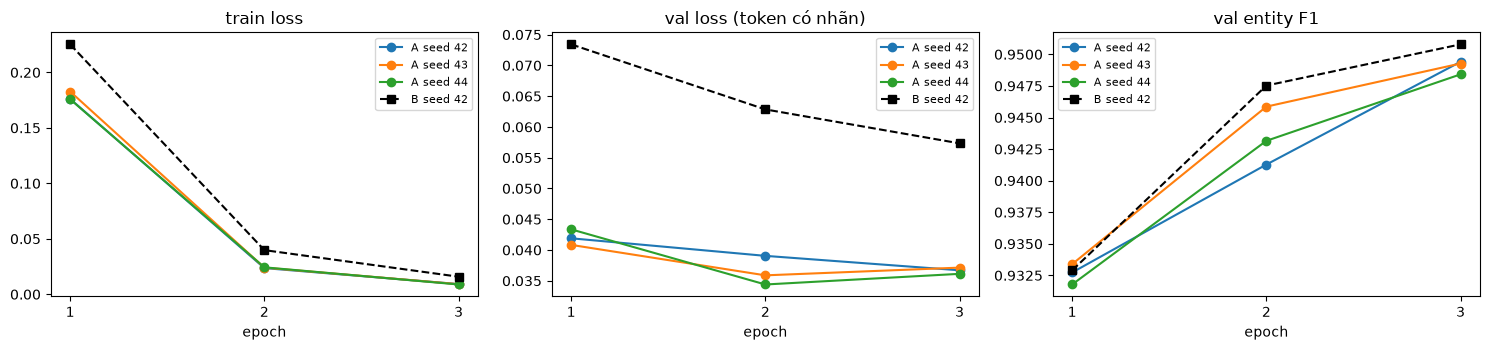

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for s in SEEDS:
    h = pd.DataFrame(resA[s]["history"]); ax[0].plot(h.epoch, h.train_loss, "o-", label=f"A seed {s}"); ax[1].plot(h.epoch, h.val_loss, "o-", label=f"A seed {s}"); ax[2].plot(h.epoch, h.val_entity_f1, "o-", label=f"A seed {s}")
h = pd.DataFrame(resB["history"]); ax[0].plot(h.epoch, h.train_loss, "s--", c="k", label="B seed 42"); ax[1].plot(h.epoch, h.val_loss, "s--", c="k", label="B seed 42"); ax[2].plot(h.epoch, h.val_entity_f1, "s--", c="k", label="B seed 42")
for a, t in zip(ax, ["train loss", "val loss (token có nhãn)", "val entity F1"]): a.set_title(t); a.set_xlabel("epoch"); a.set_xticks([1, 2, 3]); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("learning_curves.png", dpi=130); plt.show()

## 7. Experiment 2 — Baseline vs Pretrained Transformer (cùng test set)

Entity-level micro P/R/F1 (khớp tuyệt đối ranh giới + loại). Transformer báo cáo từng seed và trung bình ± độ lệch chuẩn (3 seed 42/43/44, Strategy A).

In [9]:
def row(name, em, tm, extra=None):
    d = {"Model": name, "Precision": em["micro"]["precision"], "Recall": em["micro"]["recall"], "F1": em["micro"]["f1"], "Macro-F1 (4 types)": em["macro"]["f1"],
         "token acc": tm["accuracy"], "token F1 (non-O)": tm["f1"]}
    return d
rows = [row("Baseline (LogReg)", resBase["test"]["entity"], resBase["test"]["token"])]
for s in SEEDS: rows.append(row(f"Pretrained Transformer (A, seed {s})", resA[s]["test"]["entity"], resA[s]["test"]["token"]))
T = pd.DataFrame(rows[1:]); mean, std = T.iloc[:, 1:].mean(), T.iloc[:, 1:].std(ddof=1)
rows.append({"Model": "Pretrained Transformer (A, mean of 3 seeds)", **mean.to_dict()}); rows.append({"Model": "   ± std", **std.to_dict()})
rows.append(row("Pretrained Transformer (B, seed 42)", resB["test"]["entity"], resB["test"]["token"]))
EX2 = pd.DataFrame(rows); display(EX2.round(4))
b, m_ = resBase["test"]["entity"]["micro"], mean
md(f"**Kết quả**: baseline F1 = {b['f1']:.4f} → Transformer {m_['F1']:.4f} ± {std['F1']:.4f} (+{m_['F1'] - b['f1']:.4f}). Precision {b['precision']:.4f} → {m_['Precision']:.4f}, recall {b['recall']:.4f} → {m_['Recall']:.4f}. "
   f"Token accuracy chỉ {resBase['test']['token']['accuracy']:.4f} → {m_['token acc']:.4f} (+{m_['token acc'] - resBase['test']['token']['accuracy']:.4f}) vì ~{100 * resBase['test']['token']['majority_O_accuracy']:.0f}% token là `O`: cùng một cải thiện trông nhỏ ở accuracy nhưng lớn ở entity-F1.")

,Model,Precision,Recall,F1,Macro-F1 (4 types),token acc,token F1 (non-O)
0,Baseline (LogReg),0.7489,0.8109,0.7786,0.7774,0.9618,0.8272
1,"Pretrained Transformer (A, seed 42)",0.9090,0.9230,0.9159,0.9013,0.9833,0.9274
2,"Pretrained Transformer (A, seed 43)",0.9045,0.9173,0.9109,0.8963,0.9823,0.9230
3,"Pretrained Transformer (A, seed 44)",0.9062,0.9201,0.9131,0.8979,0.9825,0.9240
4,"Pretrained Transformer (A, mean of 3 seeds)",0.9066,0.9201,0.9133,0.8985,0.9827,0.9248
5,± std,0.0023,0.0028,0.0025,0.0026,0.0006,0.0023
6,"Pretrained Transformer (B, seed 42)",0.9062,0.9187,0.9124,0.8975,0.9825,0.9242


**Kết quả**: baseline F1 = 0.7786 → Transformer 0.9133 ± 0.0025 (+0.1347). Precision 0.7489 → 0.9066, recall 0.8109 → 0.9201. Token accuracy chỉ 0.9618 → 0.9827 (+0.0209) vì ~83% token là `O`: cùng một cải thiện trông nhỏ ở accuracy nhưng lớn ở entity-F1.

## 8. Experiment 3 — Entity-level vs token-level evaluation

Ví dụ của đề: gold `New York → B-LOC I-LOC`, prediction `B-LOC O`: token `New` đúng nhưng entity `New York` không được nhận diện. Dưới đây định lượng khoảng cách này trên test thật.

In [10]:
def partial_stats(gold, pred):
    # gold entity sai nhưng có ít nhất 1 token trong span đúng nhãn BIO chính xác ("token-correct, entity-wrong")
    g, p = nc.entity_set(gold), nc.entity_set(pred); wrong = g - p; partial = 0; frac = []
    for (i, t, s, e) in wrong:
        ok = sum(gold[i][j] == pred[i][j] for j in range(s, e)); frac.append(ok / (e - s)); partial += ok > 0
    return len(g), len(wrong), partial, float(np.mean(frac))
rows = []
for name, pr in [("Baseline", predBase), ("Transformer (A, s42)", predT)]:
    tm, em = nc.token_metrics(gold, pr), nc.entity_metrics(gold, pr)["micro"]; n_g, n_w, n_p, fr = partial_stats(gold, pr)
    rows.append({"model": name, "token acc": tm["accuracy"], "token F1 (non-O)": tm["f1"], "entity F1": em["f1"], "gap (token F1 − entity F1)": tm["f1"] - em["f1"],
                 "gold entities": n_g, "entity sai": n_w, "…trong đó có ≥1 token đúng": n_p, "…% token đúng trung bình trong entity sai": fr,
                 "I-X không hợp lệ": sum(nc.invalid_bio_transitions(x) for x in pr)})
EX3 = pd.DataFrame(rows); display(EX3.round(4))
r0, r1 = EX3.iloc[0], EX3.iloc[1]
md(f"- Baseline: token F1 (không-`O`) {r0['token F1 (non-O)']:.4f} vs entity F1 {r0['entity F1']:.4f}; Transformer: {r1['token F1 (non-O)']:.4f} vs {r1['entity F1']:.4f}. Entity-level luôn thấp hơn vì một entity chỉ đúng khi **mọi** token của nó đúng cùng lúc.\n"
   f"- Trong {int(r1['entity sai'])} entity gold bị sai của Transformer, {int(r1['…trong đó có ≥1 token đúng'])} ({100*r1['…trong đó có ≥1 token đúng']/r1['entity sai']:.0f}%) vẫn có ít nhất một token đúng nhãn — token-level sẽ tính chúng là 'đúng một phần', entity-level tính là sai hoàn toàn.\n"
   f"- Baseline phân loại token độc lập nên sinh {int(r0['I-X không hợp lệ'])} chỗ `I-X` vô nghĩa (so với {int(r1['I-X không hợp lệ'])} của Transformer): chuỗi nhãn đó không phải entity hợp lệ.")

,model,token acc,token F1 (non-O),entity F1,gap (token F1 − entity F1),gold entities,entity sai,…trong đó có ≥1 token đúng,…% token đúng trung bình trong entity sai,I-X không hợp lệ
0,Baseline,0.9618,0.8272,0.7786,0.0486,5648,1068,307,0.1590,450
1,"Transformer (A, s42)",0.9833,0.9274,0.9159,0.0114,5648,435,63,0.0999,43


- Baseline: token F1 (không-`O`) 0.8272 vs entity F1 0.7786; Transformer: 0.9274 vs 0.9159. Entity-level luôn thấp hơn vì một entity chỉ đúng khi **mọi** token của nó đúng cùng lúc.
- Trong 435 entity gold bị sai của Transformer, 63 (14%) vẫn có ít nhất một token đúng nhãn — token-level sẽ tính chúng là 'đúng một phần', entity-level tính là sai hoàn toàn.
- Baseline phân loại token độc lập nên sinh 450 chỗ `I-X` vô nghĩa (so với 43 của Transformer): chuỗi nhãn đó không phải entity hợp lệ.

## 9. Experiment 4 — Entity type analysis

Ngoài P/R/F1 theo loại, thu thập các yếu tố để giải thích: số entity train, tỉ lệ entity test mà *chuỗi bề mặt chưa từng là entity ở train*, độ dài trung bình, và độ mơ hồ (tỉ lệ entity test mà chuỗi bề mặt xuất hiện ở train với **loại khác**).

In [11]:
train_ents = collections.defaultdict(collections.Counter)         # surface -> Counter(type)
for r in data["train"]:
    for t, s, e in nc.tags_to_entities(r["tags"]): train_ents[" ".join(r["tokens"][s:e])][t] += 1
def surf(i, t, s, e): return " ".join(test[i]["tokens"][s:e])
g_set = nc.entity_set(gold)
emB, emT = nc.entity_metrics(gold, predBase), nc.entity_metrics(gold, predT)
emTs = [nc.entity_metrics(gold, predA[s]) for s in SEEDS]
rows, ent_rows = [], []
for typ in nc.ENTITY_TYPES:
    G = [x for x in g_set if x[1] == typ]
    unseen = np.mean([surf(*x) not in train_ents for x in G]); amb = np.mean([surf(*x) in train_ents and typ not in train_ents[surf(*x)] for x in G])
    ntr = sum(1 for r in data["train"] for t, _, _ in nc.tags_to_entities(r["tags"]) if t == typ)
    rows.append({"entity": typ, "train entities": ntr, "test support": len(G), "mean length": np.mean([x[3] - x[2] for x in G]), "% unseen surface": 100 * unseen, "% seen but other type in train": 100 * amb,
                 "Baseline P": emB[typ]["precision"], "Baseline R": emB[typ]["recall"], "Baseline F1": emB[typ]["f1"],
                 "Transformer P": emT[typ]["precision"], "Transformer R": emT[typ]["recall"], "Transformer F1": emT[typ]["f1"],
                 "Transformer F1 (mean 3 seeds)": np.mean([e[typ]["f1"] for e in emTs]), "std": np.std([e[typ]["f1"] for e in emTs], ddof=1)})
EX4 = pd.DataFrame(rows).set_index("entity"); display(EX4.round(3).T)
best, worst = EX4["Transformer F1"].idxmax(), EX4["Transformer F1"].idxmin()
md(f"Transformer: F1 cao nhất ở **{best}** ({EX4.loc[best,'Transformer F1']:.3f}), thấp nhất ở **{worst}** ({EX4.loc[worst,'Transformer F1']:.3f}); baseline: cao nhất {EX4['Baseline F1'].idxmax()} ({EX4['Baseline F1'].max():.3f}), thấp nhất {EX4['Baseline F1'].idxmin()} ({EX4['Baseline F1'].min():.3f}). "
   f"Khoảng cách Transformer − baseline lớn nhất ở **{(EX4['Transformer F1'] - EX4['Baseline F1']).idxmax()}** (+{(EX4['Transformer F1'] - EX4['Baseline F1']).max():.3f}). "
   "Mối liên hệ với số lượng train / pattern từ vựng / mơ hồ / ngữ cảnh / ranh giới được diễn giải trong `error_analysis.md` mục 3 dựa trên bảng này.")

entity,PER,ORG,LOC,MISC
train entities,6600.000,6321.000,7140.000,3438.000
test support,1617.000,1661.000,1668.000,702.000
mean length,1.715,1.503,1.154,1.308
% unseen surface,85.281,41.902,17.866,32.336
% seen but other type in train,0.247,4.154,0.480,0.570
Baseline P,0.779,0.670,0.788,0.766
Baseline R,0.854,0.710,0.883,0.779
Baseline F1,0.815,0.689,0.833,0.773
Transformer P,0.960,0.894,0.930,0.784
Transformer R,0.965,0.905,0.936,0.838


Transformer: F1 cao nhất ở **PER** (0.962), thấp nhất ở **MISC** (0.810); baseline: cao nhất LOC (0.833), thấp nhất ORG (0.689). Khoảng cách Transformer − baseline lớn nhất ở **ORG** (+0.211). Mối liên hệ với số lượng train / pattern từ vựng / mơ hồ / ngữ cảnh / ranh giới được diễn giải trong `error_analysis.md` mục 3 dựa trên bảng này.

## 10. Experiment 5 — Entity length

Entity xếp nhóm theo chính độ dài của nó (gold theo độ dài gold, prediction theo độ dài prediction); TP = khớp tuyệt đối. Thêm cột kiểm tra giả thuyết *pⁿ*: nếu mỗi token trong entity đúng độc lập với xác suất *p* thì entity *n* token đúng ≈ *pⁿ* (p đo bằng accuracy nhãn BIO trên các token của gold entity có độ dài *n*).

,gold support,Baseline F1,Transformer P,Transformer R,Transformer F1,Transformer F1 (mean 3 seeds),std,token acc in gold entities p,p^n (n = mean length)
entity length,,,,,,,,,
1,3574,0.761,0.901,0.919,0.910,0.909,0.003,0.923,0.923
2,1776,0.838,0.929,0.935,0.932,0.929,0.004,0.945,0.893
3,236,0.663,0.901,0.890,0.896,0.881,0.012,0.924,0.788
4+,62,0.545,0.826,0.919,0.870,0.844,0.022,0.964,0.849


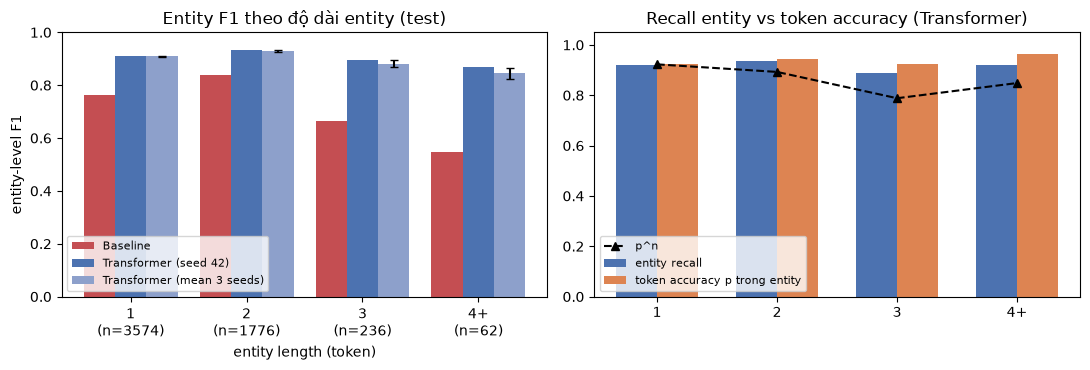

Transformer F1 theo độ dài 1/2/3/4+: 0.910 / 0.932 / 0.896 / 0.870; baseline: 0.761 / 0.838 / 0.663 / 0.545. Support nhóm 4+ chỉ 62 entity nên sai số lớn (std 3 seed = 0.022). Đối chiếu với prediction P2 ở mục *Đối chiếu prediction* (README).

In [12]:
lenB, lenT = nc.entity_metrics_by_length(gold, predBase), nc.entity_metrics_by_length(gold, predT)
lenTs = [nc.entity_metrics_by_length(gold, predA[s]) for s in SEEDS]
buckets = {"1": (1, 1), "2": (2, 2), "3": (3, 3), "4+": (4, 99)}
rows = []
for k, (lo, hi) in buckets.items():
    toks = [(gold[i][j] == predT[i][j]) for (i, t, s, e) in g_set if lo <= e - s <= hi for j in range(s, e)]
    n_avg = np.mean([e - s for (i, t, s, e) in g_set if lo <= e - s <= hi]); p = float(np.mean(toks))
    rows.append({"entity length": k, "gold support": lenT[k]["support"], "Baseline F1": lenB[k]["f1"], "Transformer P": lenT[k]["precision"], "Transformer R": lenT[k]["recall"], "Transformer F1": lenT[k]["f1"],
                 "Transformer F1 (mean 3 seeds)": np.mean([l[k]["f1"] for l in lenTs]), "std": np.std([l[k]["f1"] for l in lenTs], ddof=1), "token acc in gold entities p": p, "p^n (n = mean length)": p ** n_avg})
EX5 = pd.DataFrame(rows).set_index("entity length"); display(EX5.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); x = np.arange(4); wd = .27
ax[0].bar(x - wd, EX5["Baseline F1"], wd, label="Baseline", color="#C44E52"); ax[0].bar(x, EX5["Transformer F1"], wd, label="Transformer (seed 42)", color="#4C72B0")
ax[0].bar(x + wd, EX5["Transformer F1 (mean 3 seeds)"], wd, yerr=EX5["std"], label="Transformer (mean 3 seeds)", color="#8DA0CB", capsize=3)
ax[0].set_xticks(x); ax[0].set_xticklabels([f"{k}\n(n={int(v)})" for k, v in zip(EX5.index, EX5["gold support"])]); ax[0].set_ylim(0, 1); ax[0].set_xlabel("entity length (token)"); ax[0].set_ylabel("entity-level F1"); ax[0].legend(fontsize=8); ax[0].set_title("Entity F1 theo độ dài entity (test)")
ax[1].bar(x - .17, EX5["Transformer R"], .34, label="entity recall", color="#4C72B0"); ax[1].bar(x + .17, EX5["token acc in gold entities p"], .34, label="token accuracy p trong entity", color="#DD8452")
ax[1].plot(x, EX5["p^n (n = mean length)"], "k^--", label="p^n"); ax[1].set_xticks(x); ax[1].set_xticklabels(EX5.index); ax[1].set_ylim(0, 1.05); ax[1].legend(fontsize=8); ax[1].set_title("Recall entity vs token accuracy (Transformer)")
plt.tight_layout(); plt.savefig("entity_length_analysis.png", dpi=140); plt.show()
f = EX5["Transformer F1"]
md(f"Transformer F1 theo độ dài 1/2/3/4+: {f['1']:.3f} / {f['2']:.3f} / {f['3']:.3f} / {f['4+']:.3f}; baseline: {EX5.loc['1','Baseline F1']:.3f} / {EX5.loc['2','Baseline F1']:.3f} / {EX5.loc['3','Baseline F1']:.3f} / {EX5.loc['4+','Baseline F1']:.3f}. "
   f"Support nhóm 4+ chỉ {int(EX5.loc['4+','gold support'])} entity nên sai số lớn (std 3 seed = {EX5.loc['4+','std']:.3f}). Đối chiếu với prediction P2 ở mục *Đối chiếu prediction* (README).")

## 11. Rare entity (prediction P3) — entity chưa từng xuất hiện ở train có khó hơn không?

Nhóm gold entity test theo số lần chuỗi bề mặt của nó xuất hiện như *entity* trong train: 0 (unseen), 1–4 (rare), ≥ 5 (frequent); report **recall** (gold entity khớp tuyệt đối).

In [13]:
def recall_by(pred, groups):
    p = nc.entity_set(pred); out = {}
    for k, G in groups.items(): out[k] = (np.mean([x in p for x in G]), len(G))
    return out
cnt = lambda x: sum(train_ents.get(surf(*x), {}).values())
groups = collections.defaultdict(list)
for x in g_set:
    c = cnt(x); groups["unseen (0)" if c == 0 else "rare (1-4)" if c < 5 else "frequent (>=5)"].append(x)
rows = []
for name, pr in [("Baseline", predBase), ("Transformer (A, s42)", predT)] + [(f"Transformer (A, s{s})", predA[s]) for s in (43, 44)]:
    r_ = recall_by(pr, groups); rows.append({"model": name, **{f"{k} recall": v[0] for k, v in r_.items()}})
RR = pd.DataFrame(rows).set_index("model")[["unseen (0) recall", "rare (1-4) recall", "frequent (>=5) recall"]]; display(RR.round(4))
# precision/recall theo "bề mặt đã/chưa từng là entity ở train" (prediction P1: baseline có precision > recall trên entity chưa gặp?)
seen_set = set(train_ents)
rows = []
for name, pr in [("Baseline", predBase), ("Transformer (A, s42)", predT)]:
    P_ = nc.entity_set(pr)
    for grp, f in [("unseen surface", lambda x: surf(*x) not in seen_set), ("seen surface", lambda x: surf(*x) in seen_set)]:
        Gs, Ps = {x for x in g_set if f(x)}, {x for x in P_ if f(x)}; tp = len(Gs & Ps)
        rows.append({"model": name, "group": grp, "precision": tp / len(Ps), "recall": tp / len(Gs), "#pred": len(Ps), "#gold": len(Gs)})
display(pd.DataFrame(rows).round(4))
sup = {k: len(v) for k, v in groups.items()}
md(f"Support: {sup}. Recall chênh frequent − unseen: baseline = {RR.loc['Baseline','frequent (>=5) recall'] - RR.loc['Baseline','unseen (0) recall']:.3f}, Transformer (seed 42) = {RR.loc['Transformer (A, s42)','frequent (>=5) recall'] - RR.loc['Transformer (A, s42)','unseen (0) recall']:.3f}.")

,unseen (0) recall,rare (1-4) recall,frequent (>=5) recall
model,,,
Baseline,0.6846,0.8430,0.9538
"Transformer (A, s42)",0.8835,0.9318,0.9683
"Transformer (A, s43)",0.8723,0.9329,0.9663
"Transformer (A, s44)",0.8777,0.9349,0.9663


,model,group,precision,recall,#pred,#gold
0,Baseline,unseen surface,0.5993,0.6846,2970,2600
1,Baseline,seen surface,0.8900,0.9186,3146,3048
2,"Transformer (A, s42)",unseen surface,0.8530,0.8835,2693,2600
3,"Transformer (A, s42)",seen surface,0.9586,0.9567,3042,3048


Support: {'unseen (0)': 2600, 'rare (1-4)': 968, 'frequent (>=5)': 2080}. Recall chênh frequent − unseen: baseline = 0.269, Transformer (seed 42) = 0.085.

## 12. Confusion matrix (mức word, nhãn BIO)

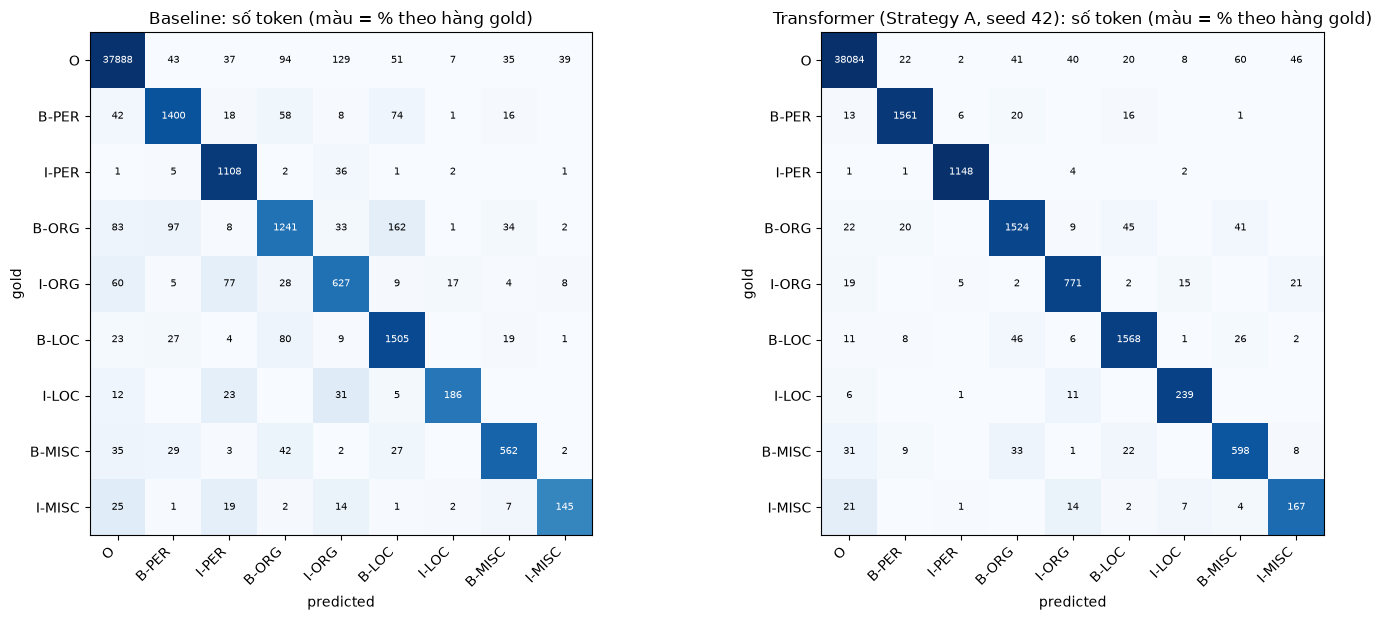

Nhầm lẫn lớn nhất của Transformer (gold → pred: số token): `O`→`B-MISC`: 60; `O`→`I-MISC`: 46; `B-LOC`→`B-ORG`: 46; `B-ORG`→`B-LOC`: 45; `O`→`B-ORG`: 41; `B-ORG`→`B-MISC`: 41. Nhầm giữa `B-X`/`I-X` cùng loại phản ánh lỗi ranh giới; nhầm giữa loại khác nhau (vd. `B-ORG`↔`B-LOC`) là lỗi loại; nhầm với `O` là entity bị bỏ sót/thừa.

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
for ax, (name, pr) in zip(axes, [("Baseline", predBase), ("Transformer (Strategy A, seed 42)", predT)]):
    cm = nc.confusion_counts(gold, pr); cmn = cm / cm.sum(1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.set_xticks(range(9)); ax.set_yticks(range(9)); ax.set_xticklabels(nc.LABELS, rotation=45, ha="right"); ax.set_yticklabels(nc.LABELS)
    for i in range(9):
        for j in range(9):
            if cm[i, j]: ax.text(j, i, f"{cm[i,j]}", ha="center", va="center", fontsize=7, color="white" if cmn[i, j] > .5 else "black")
    ax.set_xlabel("predicted"); ax.set_ylabel("gold"); ax.set_title(f"{name}: số token (màu = % theo hàng gold)")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=140); plt.show()
cm = nc.confusion_counts(gold, predT); off = [(nc.LABELS[i], nc.LABELS[j], int(cm[i, j])) for i in range(9) for j in range(9) if i != j]; off.sort(key=lambda x: -x[2])
md("Nhầm lẫn lớn nhất của Transformer (gold → pred: số token): " + "; ".join(f"`{a}`→`{b}`: {n}" for a, b, n in off[:6]) + ". Nhầm giữa `B-X`/`I-X` cùng loại phản ánh lỗi ranh giới; nhầm giữa loại khác nhau (vd. `B-ORG`↔`B-LOC`) là lỗi loại; nhầm với `O` là entity bị bỏ sót/thừa.")

## 13. Experiment 6 — Error analysis

Phân loại lỗi tự động (`nc.categorize_errors`) rồi chọn **mẫu cố định, seed 42** (không cherry-pick): 5 *spurious entity* (false positive), 5 *missing entity* (false negative), 5 *boundary error* (đúng loại, sai span) từ **toàn bộ** lỗi của Transformer chính (A, seed 42); thêm 3 *wrong type* để bao phủ loại lỗi thứ tư. `Explanation` được viết tay sau khi đọc từng câu (cột cuối, cũng nằm trong `error_analysis.md`).

In [15]:
def cat_all(pred):
    out = []
    for i, (g, p) in enumerate(zip(gold, pred)):
        for e in nc.categorize_errors(g, p): out.append({"i": i, **e})
    return out
errT, errB = cat_all(predT), cat_all(predBase)
cc = pd.DataFrame({"Baseline": collections.Counter(e["category"] for e in errB), "Transformer (A, s42)": collections.Counter(e["category"] for e in errT)}).fillna(0).astype(int)
cc.loc["total"] = cc.sum(); display(cc)
rng = random.Random(42)
def pick(cat, k): pool = [e for e in errT if e["category"] == cat]; return rng.sample(pool, k)
SEL = pick("spurious", 5) + pick("missing", 5) + pick("boundary", 5) + pick("wrong_type", 3)
def fmt_ent(i, ent, words):
    return "—" if ent is None else f"{' '.join(words[ent[1]:ent[2]])} [{ent[0]}]"
def mark(i):
    w, g, p = test[i]["tokens"], gold[i], predT[i]; return " ".join(w)
rows = []
for e in SEL:
    i = e["i"]; w = test[i]["tokens"]
    span = e["gold"] or e["pred"]; base_same = any(be["i"] == i and (be["gold"] == e["gold"] and be["pred"] == e["pred"]) for be in errB)
    rows.append({"id": test[i]["id"], "error type": e["category"], "text": " ".join(w), "gold": fmt_ent(i, e["gold"], w), "Transformer pred": fmt_ent(i, e["pred"], w),
                 "baseline same error": base_same, "conf (pred tok)": round(float(np.nanmean(confT[i][(e["pred"] or e["gold"])[1]:(e["pred"] or e["gold"])[2]])), 3)})
ERR = pd.DataFrame(rows); display(ERR)

,Baseline,"Transformer (A, s42)"
wrong_type,508,229
spurious,315,148
boundary,317,78
missing,143,63
boundary+type,100,65
total,1383,583


,id,error type,text,gold,Transformer pred,baseline same error,conf (pred tok)
0,527,spurious,WESTERN DIVISION,—,WESTERN DIVISION [MISC],True,0.998
1,359,spurious,NORTHEAST DIVISION,—,NORTHEAST DIVISION [MISC],True,0.988
2,1611,spurious,Slaughter Heifers - Select and Choice 2-3 1050-1100 lbs 67.00 .,—,Slaughter Heifers [ORG],False,0.609
3,1434,spurious,Maize ( Dent ) 113 114 113.7 112,—,Maize [PER],True,0.949
4,1297,spurious,"A meeting with the Pope is also planned , "" Dariusz Rosati told a news conference .",—,Pope [PER],False,0.562
5,356,missing,League teams after games played on Thursday ( tabulate under,League [ORG],—,True,0.888
6,2350,missing,In a stand some analysts linked to controversy over Singapore 's caning of an American...,then-U.S. [MISC],—,True,1.000
7,291,missing,CRICKET - WEST INDIES 172 ALL OUT IN 49.2 OVERS V AUSTRALIA .,WEST INDIES [LOC],—,False,0.919
8,2267,missing,"Deligst 20/11/96 5,500 Indonesia",Deligst [MISC],—,True,0.844
9,3307,missing,Association games on Friday ( home team in CAPS ) :,Association [ORG],—,True,0.982


In [16]:
EXPL = json.loads(Path("error_explanations.json").read_text(encoding="utf8")) if Path("error_explanations.json").exists() else {}
ERR["explanation"] = [EXPL.get(f"{r['id']}|{r['error type']}|{r['gold']}|{r['Transformer pred']}", "(chưa viết)") for _, r in ERR.iterrows()]
missing_expl = int((ERR["explanation"] == "(chưa viết)").sum())
for _, r in ERR.iterrows():
    md(f"**[{r['id']}] {r['error type']}** — gold: `{r['gold']}`; pred: `{r['Transformer pred']}`; baseline cùng lỗi: {r['baseline same error']}\n\n> {r['text']}\n\n{r['explanation']}")
md(f"Số mẫu chưa có giải thích: {missing_expl}.")
evid = [{"id": r["id"], "error_type": r["error type"], "text": r["text"], "gold": r["gold"], "transformer_pred": r["Transformer pred"], "baseline_same_error": bool(r["baseline same error"]),
         "explanation": r["explanation"]} for _, r in ERR.iterrows()]
Path("error_analysis_evidence.json").write_text(json.dumps({"model": nc.run_name(cfgA[42]), "selection": "seed 42; 5 spurious + 5 missing + 5 boundary + 3 wrong_type", "counts": cc.to_dict(), "samples": evid}, ensure_ascii=False, indent=1), encoding="utf8")

**[527] spurious** — gold: `—`; pred: `WESTERN DIVISION [MISC]`; baseline cùng lỗi: True

> WESTERN DIVISION

Spurious (conf 0.998). Gold gán `O` nhưng model (và baseline) cùng đoán MISC cho `WESTERN DIVISION`. Đây chủ yếu là **nhãn không nhất quán trong CoNLL**: trong train, từ `DIVISION` mang nhãn `I-MISC` 48 lần và `O` 46 lần, tức gần như tung đồng xu; model học theo thống kê (tên giải/khu vực IN HOA ≈ MISC) và đoán MISC rất tự tin. Không phải lỗi hiểu ngữ cảnh mà là ambiguous annotation.

**[359] spurious** — gold: `—`; pred: `NORTHEAST DIVISION [MISC]`; baseline cùng lỗi: True

> NORTHEAST DIVISION

Spurious (conf 0.988). Cùng nguyên nhân với câu 527: tên division IN HOA trong bảng xếp hạng NBA/NHL, gold `O`, train tách đôi 48 `I-MISC` / 46 `O` cho từ `DIVISION`. Baseline cũng sai giống hệt — cho thấy đây là nhiễu nhãn chứ không phải điểm yếu riêng của Transformer.

**[1611] spurious** — gold: `—`; pred: `Slaughter Heifers [ORG]`; baseline cùng lỗi: False

> Slaughter Heifers - Select and Choice 2-3 1050-1100 lbs 67.00 .

Spurious (conf 0.609, thấp). Dòng báo cáo giá gia súc (`Slaughter Heifers - Select and Choice ...`) là domain/định dạng hiếm trong train: hai từ viết hoa liền nhau, không có cue ngữ cảnh nào của tổ chức. `Slaughter` và `Heifers` đều bị WordPiece tách (`S ##lau ##ghter`, `He ##ifer ##s`) nên biểu diễn nghèo; model suy diễn 'cụm viết hoa ≈ tên riêng ≈ ORG'. Rare/out-of-pattern text + subword; confidence thấp là tín hiệu đúng (baseline không lỗi câu này).

**[1434] spurious** — gold: `—`; pred: `Maize [PER]`; baseline cùng lỗi: True

> Maize ( Dent ) 113 114 113.7 112

Spurious (conf 0.949, cao). Dòng giá ngũ cốc `Maize ( Dent ) 113 114 ...` có đúng khuôn của dòng thể thao `Tên ( Đội ) số số ...`: trong train, từ viết hoa đứng ngay trước `(` mang nhãn `I-PER` 1,530 lần (so với 170 `O`). Model dùng pattern vị trí/định dạng thay vì nghĩa của `Maize`/`Dent` (cũng bị tách: `Mai ##ze`) nên đoán PER rất tự tin; baseline (feature `+1:lower=(`) cùng đoán `B-PER` cho `Maize`; Transformer còn thêm `Dent` thành PER thứ hai. Ví dụ điển hình của lỗi context-dependent bị khuôn bề mặt đánh lừa.

**[1297] spurious** — gold: `—`; pred: `Pope [PER]`; baseline cùng lỗi: False

> A meeting with the Pope is also planned , " Dariusz Rosati told a news conference .

Spurious (conf 0.562, thấp). `the Pope` là chức danh/vai trò, không phải tên riêng; gold `O`. Trong train `Pope` chỉ xuất hiện 1 lần (`B-PER`, trong `Pope John Paul II`) nên model coi `Pope` viết hoa giữa câu là người. Ranh giới khái niệm 'entity có tên' vs 'danh xưng' mơ hồ; baseline cũng sai nhưng theo kiểu khác (`B-LOC`). Rare entity + ambiguous entity.

**[356] missing** — gold: `League [ORG]`; pred: `—`; baseline cùng lỗi: True

> League teams after games played on Thursday ( tabulate under

Missing (conf 0.888 cho `O`). Câu bị cắt (`League teams after games played on Thursday ( tabulate under`) — phần đầu tên giải (vd. `National Hockey`) nằm ở dòng trước, gold chỉ còn `League` = ORG. Không còn ngữ cảnh để model suy ra tổ chức nên coi `League` là danh từ thường ở đầu câu. Lỗi do **dữ liệu bị cắt/nhiễu ngữ cảnh** chứ không phải model yếu; baseline cũng bỏ sót.

... (10 outputs left out)

**[421] wrong_type** — gold: `Philadelphia [LOC]`; pred: `Philadelphia [ORG]`; baseline cùng lỗi: True

> Philadelphia , which fell from an NFC East tie with the Dallas Cowboys and Washington Redskins , go on the road against the New York Jets and then entertain Arizona .

Wrong type (cả hai model). `Philadelphia, which fell from an NFC East tie ... go on the road against the New York Jets` rõ ràng chỉ *đội* NFL (ORG); gold ghi LOC. Train: `Philadelphia` = `B-ORG` 11 lần, `B-LOC` 1 lần. Đây là phân biệt LOC/ORG phụ thuộc ngữ cảnh mà model làm đúng về ngữ nghĩa nhưng sai theo gold; xem thêm mục context analysis (`CHICAGO`, `WASHINGTON`: nhãn phụ thuộc cả layout `X AT Y` vs bảng điểm).

**[909] wrong_type** — gold: `Democratic Convention [MISC]`; pred: `Democratic Convention [ORG]`; baseline cùng lỗi: False

> * The Democratic Convention signed an agreement on government and parliamentary support with its coalition partners the Social Democratic Union and the Hungarian Democratic Union ( UDMR ) .

Wrong type (baseline lại đoán đúng MISC). `The Democratic Convention` là một đảng/liên minh chính trị ở Romania, đứng cùng `Social Democratic Union`, `Hungarian Democratic Union` (UDMR) — theo ngữ nghĩa là ORG và model đoán ORG; gold ghi MISC. Tên đảng/liên minh chính trị là ranh giới ORG vs MISC nổi tiếng mơ hồ của CoNLL; không thể xác định từ câu này đâu là nhãn 'đúng'. Ambiguous entity.

Số mẫu chưa có giải thích: 0.

12663

## 14. Context analysis (mục 24) — cùng surface form, khác entity type

Tìm trong test set các chuỗi bề mặt xuất hiện với **≥ 2 loại gold khác nhau**; xem baseline (features rời rạc) và Transformer (biểu diễn ngữ cảnh) xử lý thế nào. Thêm phép đo: cosine giữa vector lớp cuối ở subword đầu của từ đó trong các câu khác nhau (embedding tĩnh = vector đầu vào giống hệt nhau ⇒ cosine = 1 theo định nghĩa).

In [17]:
occ = collections.defaultdict(list)
for (i, t, s, e) in sorted(g_set): occ[surf(i, t, s, e)].append((i, t, s, e))
multi = {k: v for k, v in occ.items() if len({x[1] for x in v}) >= 2 and len(k.split()) == 1}
rank = sorted(multi.items(), key=lambda kv: -len(kv[1]))
pT_set, pB_set = nc.entity_set(predT), nc.entity_set(predBase)
def pred_type(pset, i, s, e):
    hits = [x for x in pset if x[0] == i and x[2] < e and s < x[3]]; return "/".join(f"{x[1]}" if (x[2], x[3]) == (s, e) else f"{x[1]}(span {x[2]}-{x[3]})" for x in hits) or "O"
rows = []
for k, v in rank[:10]:
    types = collections.Counter(x[1] for x in v)
    for (i, t, s, e) in v[:6]:
        rows.append({"surface": k, "gold types in test": dict(types), "gold": t, "Transformer": pred_type(pT_set, i, s, e), "Baseline": pred_type(pB_set, i, s, e), "context": " ".join(test[i]["tokens"])[:85]})
CTX = pd.DataFrame(rows); display(CTX)

,surface,gold types in test,gold,Transformer,Baseline,context
0,Barcelona,"{'LOC': 2, 'ORG': 22}",LOC,LOC,LOC,"FIFA 's players ' status committee , meeting in Barcelona , decided that although the"
1,Barcelona,"{'LOC': 2, 'ORG': 22}",ORG,ORG,ORG,Barcelona ( Spain ) 9 4 5 13
2,Barcelona,"{'LOC': 2, 'ORG': 22}",ORG,ORG,ORG,"Goalkeepers - Vitor Baia ( Barcelona , Spain ) , Rui Correia ( Braga ) :"
3,Barcelona,"{'LOC': 2, 'ORG': 22}",ORG,ORG,ORG,"Defenders - Paulinho Santos ( Porto ) , Sergio Conceicao ( Porto ) , Joao Manuel Pint"
4,Barcelona,"{'LOC': 2, 'ORG': 22}",ORG,ORG,ORG,"Midfielders - Rui Barros ( Porto ) , Jose Barroso ( Porto ) , Luis Figo ( Barcelona )"
5,Barcelona,"{'LOC': 2, 'ORG': 22}",ORG,ORG,LOC,Spanish first division match between Real Madrid and Barcelona :
6,CHICAGO,"{'ORG': 7, 'LOC': 6}",ORG,ORG,ORG,CHICAGO 12 12 3 71 67 27
7,CHICAGO,"{'ORG': 7, 'LOC': 6}",LOC,LOC,LOC,MONTREAL AT CHICAGO
8,CHICAGO,"{'ORG': 7, 'LOC': 6}",ORG,ORG,ORG,CHICAGO 17 1 .944 -
9,CHICAGO,"{'ORG': 7, 'LOC': 6}",ORG,ORG,ORG,CHICAGO 5 8 0 202 248


In [18]:
# Chọn 3 chuỗi (có >= 3 lần xuất hiện, >= 2 loại, ít nhất 1 lần mỗi loại) và đo độ giống nhau của biểu diễn
sel = [k for k, v in rank if len(v) >= 3][:3]
md(f"Các chuỗi dùng để phân tích: {sel}; số lần xuất hiện {[len(multi[k]) for k in sel]}; loại gold {[dict(collections.Counter(x[1] for x in multi[k])) for k in sel]}.")
model.eval(); rows = []
def vec(i, s):
    enc = tok(test[i]["tokens"], is_split_into_words=True, truncation=True, max_length=256, return_tensors="pt"); pos = nc.first_subword_positions(enc.word_ids(0))
    with torch.no_grad(): H = model.hidden_states(enc["input_ids"].to(device), enc["attention_mask"].to(device))[0].float()
    emb = model.encoder.embeddings.word_embeddings.weight[enc["input_ids"][0][pos[s]]].float()
    return H[pos[s]].cpu(), emb.detach().cpu()
for k in sel:
    V = [(x, *vec(x[0], x[2])) for x in multi[k]]
    same, diff, same_e, diff_e = [], [], [], []
    for a in range(len(V)):
        for b in range(a + 1, len(V)):
            cs = torch.cosine_similarity(V[a][1], V[b][1], 0).item(); ce = torch.cosine_similarity(V[a][2], V[b][2], 0).item()
            (same if V[a][0][1] == V[b][0][1] else diff).append(cs); (same_e if V[a][0][1] == V[b][0][1] else diff_e).append(ce)
    rows.append({"surface": k, "#occurrences": len(V), "contextual cos (same type)": np.mean(same) if same else np.nan, "contextual cos (different type)": np.mean(diff) if diff else np.nan,
                 "static (input embedding) cos": np.mean(same_e + diff_e)})
display(pd.DataFrame(rows).round(3))

Các chuỗi dùng để phân tích: ['Barcelona', 'CHICAGO', 'WASHINGTON']; số lần xuất hiện [24, 13, 12]; loại gold [{'LOC': 2, 'ORG': 22}, {'ORG': 7, 'LOC': 6}, {'ORG': 8, 'LOC': 4}].

,surface,#occurrences,contextual cos (same type),contextual cos (different type),static (input embedding) cos
0,Barcelona,24,0.773,0.274,1.0
1,CHICAGO,13,0.931,0.153,1.0
2,WASHINGTON,12,0.950,0.126,1.0


In [19]:
# Thống kê trên TẤT CẢ chuỗi 1 word có >= 2 loại gold và >= 3 lần xuất hiện trong test (không chỉ vài ví dụ in ở trên)
amb = {k: v for k, v in occ.items() if len(k.split()) == 1 and len({x[1] for x in v}) >= 2 and len(v) >= 3}
n_amb = sum(len(v) for v in amb.values()); rT = sum(x in pT_set for v in amb.values() for x in v) / n_amb; rB = sum(x in pB_set for v in amb.values() for x in v) / n_amb
oT = len(g_set & pT_set) / len(g_set); oB = len(g_set & pB_set) / len(g_set)
rows = [{"surface": k, "gold types": dict(collections.Counter(x[1] for x in v)), "n": len(v), "Transformer recall": np.mean([x in pT_set for x in v]), "Baseline recall": np.mean([x in pB_set for x in v])}
        for k, v in sorted(amb.items(), key=lambda kv: -len(kv[1]))[:8]]
display(pd.DataFrame(rows).round(3))
md(f"{len(amb)} chuỗi mơ hồ ({n_amb} entity gold): entity recall Transformer = {rT:.3f}, baseline = {rB:.3f} (chênh {rT - rB:+.3f}); trên toàn test: {oT:.3f} / {oB:.3f} (chênh {oT - oB:+.3f}). "
   "Chuỗi mơ hồ khó hơn trung bình ở cả hai model; baseline có feature cửa sổ ±2 nên cũng nắm được một phần ngữ cảnh (vd. `AT`), nhưng Transformer vẫn nhỉnh hơn.")

,surface,gold types,n,Transformer recall,Baseline recall
0,Barcelona,"{'LOC': 2, 'ORG': 22}",24,0.792,0.750
1,CHICAGO,"{'ORG': 7, 'LOC': 6}",13,1.000,1.000
2,WASHINGTON,"{'ORG': 8, 'LOC': 4}",12,1.000,1.000
3,American,"{'MISC': 6, 'ORG': 4}",10,1.000,0.600
4,DETROIT,"{'ORG': 7, 'LOC': 2}",9,1.000,1.000
5,DALLAS,"{'ORG': 6, 'LOC': 3}",9,0.889,0.778
6,Busang,"{'ORG': 4, 'LOC': 5}",9,0.556,0.333
7,League,"{'ORG': 6, 'LOC': 2}",8,0.250,0.000


41 chuỗi mơ hồ (258 entity gold): entity recall Transformer = 0.857, baseline = 0.775 (chênh +0.081); trên toàn test: 0.923 / 0.811 (chênh +0.112). Chuỗi mơ hồ khó hơn trung bình ở cả hai model; baseline có feature cửa sổ ±2 nên cũng nắm được một phần ngữ cảnh (vd. `AT`), nhưng Transformer vẫn nhỉnh hơn.

**Diễn giải** (viết tay, dựa trên các bảng trên): xem `error_analysis.md` mục 4 — tại sao biểu diễn ngữ cảnh có lợi thế so với biểu diễn tĩnh (LAB 03 → LAB 08 → LAB 09).

## 15. Ảnh hưởng của alignment strategy (A vs B)

Cùng seed 42, cùng siêu tham số; chỉ khác nhãn huấn luyện của subword không đầu (A: IGNORE; B: `I-X`/`O`). Cả hai decode ở subword đầu.

In [20]:
rows = []
for name, r in [("Strategy A (seed 42)", resA[42]), ("Strategy A (seed 43)", resA[43]), ("Strategy A (seed 44)", resA[44]), ("Strategy B (seed 42)", resB)]:
    rows.append({"run": name, "val entity F1": r["val"]["entity"]["micro"]["f1"], "test P": r["test"]["entity"]["micro"]["precision"], "test R": r["test"]["entity"]["micro"]["recall"], "test entity F1": r["test"]["entity"]["micro"]["f1"],
                 "test token acc": r["test"]["token"]["accuracy"], "train time (s)": r["train_time_s"], "tokens có nhãn / epoch": "203,621 (= số word)" if name.startswith("Strategy A") else "272,595"})
ALN = pd.DataFrame(rows); display(ALN.round(4))
fa = [resA[s]["test"]["entity"]["micro"]["f1"] for s in SEEDS]; fb = resB["test"]["entity"]["micro"]["f1"]
md(f"A: {np.mean(fa):.4f} ± {np.std(fa, ddof=1):.4f} (3 seed), B (1 seed): {fb:.4f}; chênh lệch B − mean(A) = {fb - np.mean(fa):+.4f}, so với độ lệch chuẩn giữa các seed của A = {np.std(fa, ddof=1):.4f}. "
   "B chỉ có một seed nên **không đủ** để kết luận B tốt hơn/kém hơn A nếu chênh lệch nằm trong cỡ std; kết luận cụ thể được nêu trong `README.md` mục 6.")

,run,val entity F1,test P,test R,test entity F1,test token acc,train time (s),tokens có nhãn / epoch
0,Strategy A (seed 42),0.9494,0.9090,0.9230,0.9159,0.9833,448.9664,"203,621 (= số word)"
1,Strategy A (seed 43),0.9493,0.9045,0.9173,0.9109,0.9823,420.7924,"203,621 (= số word)"
2,Strategy A (seed 44),0.9484,0.9062,0.9201,0.9131,0.9825,427.6605,"203,621 (= số word)"
3,Strategy B (seed 42),0.9508,0.9062,0.9187,0.9124,0.9825,363.4774,"272,595"


A: 0.9133 ± 0.0025 (3 seed), B (1 seed): 0.9124; chênh lệch B − mean(A) = -0.0009, so với độ lệch chuẩn giữa các seed của A = 0.0025. B chỉ có một seed nên **không đủ** để kết luận B tốt hơn/kém hơn A nếu chênh lệch nằm trong cỡ std; kết luận cụ thể được nêu trong `README.md` mục 6.

## 16. Information Extraction (mục 25–27) — Option A (News)

`raw text → tokenize → NER → gộp entity → {"PERSON": [...], "ORG": [...], "LOCATION": [...]}` (`information_extraction.py`; `MISC` bị bỏ). Đánh giá entity-level trên **30 câu tự viết, gold gán tay** (`ie_gold.json`, không lấy từ CoNLL): entity đúng khi khớp cả khoảng ký tự lẫn loại.

In [21]:
tagT = ie.transformer_tagger(); tagB = ie.baseline_tagger()
demo = ["Barack Obama visited Paris.", "Elon Musk said Tesla will open a new factory in Berlin, according to Reuters.",
        "Police in Chicago arrested a suspect on Friday, said the FBI. Mayor Lori Lightfoot praised the officers at City Hall."]
for t in demo:
    md(f"**Input:** {t}\n\n```json\n{json.dumps(ie.to_structured(ie.extract_entities(t, tagT)), indent=2, ensure_ascii=False)}\n```")

**Input:** Barack Obama visited Paris.

```json
{
  "PERSON": [
    "Barack Obama"
  ],
  "LOCATION": [
    "Paris"
  ]
}
```

**Input:** Elon Musk said Tesla will open a new factory in Berlin, according to Reuters.

```json
{
  "ORG": [
    "Elon",
    "Tesla",
    "Reuters"
  ],
  "PERSON": [
    "Musk"
  ],
  "LOCATION": [
    "Berlin"
  ]
}
```

**Input:** Police in Chicago arrested a suspect on Friday, said the FBI. Mayor Lori Lightfoot praised the officers at City Hall.

```json
{
  "LOCATION": [
    "Chicago",
    "City Hall"
  ],
  "ORG": [
    "FBI"
  ],
  "PERSON": [
    "Lori Lightfoot"
  ]
}
```

In [22]:
gold_ie = ie.load_gold()
evT, evB = ie.evaluate_ie(tagT, gold_ie), ie.evaluate_ie(tagB, gold_ie)
rows = []
for name, ev in [("Baseline", evB), ("Transformer (A, s42)", evT)]:
    for k in ie.IE_TYPES + ["micro"]:
        m = ev["metrics"][k]; rows.append({"model": name, "type": k, "precision": m["precision"], "recall": m["recall"], "F1": m["f1"], "TP": m["tp"], "FP": m["fp"], "FN": m["fn"]})
IE_TAB = pd.DataFrame(rows); display(IE_TAB.round(3))
md(f"30 câu, {evT['n_gold_entities']} entity gold. Transformer micro-F1 = {evT['metrics']['micro']['f1']:.3f} (P {evT['metrics']['micro']['precision']:.3f}, R {evT['metrics']['micro']['recall']:.3f}); baseline = {evB['metrics']['micro']['f1']:.3f}. "
   f"Số câu có ít nhất một lỗi: Transformer {len(evT['errors'])}/30, baseline {len(evB['errors'])}/30. (Chỉ 30 câu ⇒ khoảng tin cậy rộng; số này là minh hoạ pipeline, không thay thế test CoNLL.)")
err_rows = [{"text": e["text"], "missing (gold, không dự đoán)": [(t, ie.load_gold()[e["sent"]]["text"][s:en]) for t, s, en in e["missing"]], "spurious (dự đoán, không có trong gold)": [(t, e["text"][s:en]) for t, s, en in e["spurious"]]} for e in evT["errors"]]
md("**Câu Transformer sai** (xem `error_analysis.md` mục 5 để phân tích):"); display(pd.DataFrame(err_rows))

,model,type,precision,recall,F1,TP,FP,FN
0,Baseline,PERSON,0.741,0.952,0.833,20,7,1
1,Baseline,ORG,0.630,0.531,0.576,17,10,15
2,Baseline,LOCATION,0.875,0.972,0.921,35,5,1
3,Baseline,micro,0.766,0.809,0.787,72,22,17
4,"Transformer (A, s42)",PERSON,0.952,0.952,0.952,20,1,1
5,"Transformer (A, s42)",ORG,0.939,0.969,0.954,31,2,1
6,"Transformer (A, s42)",LOCATION,1.000,1.000,1.000,36,0,0
7,"Transformer (A, s42)",micro,0.967,0.978,0.972,87,3,2


30 câu, 89 entity gold. Transformer micro-F1 = 0.972 (P 0.967, R 0.978); baseline = 0.787. Số câu có ít nhất một lỗi: Transformer 2/30, baseline 13/30. (Chỉ 30 câu ⇒ khoảng tin cậy rộng; số này là minh hoạ pipeline, không thay thế test CoNLL.)

**Câu Transformer sai** (xem `error_analysis.md` mục 5 để phân tích):

,text,"missing (gold, không dự đoán)","spurious (dự đoán, không có trong gold)"
0,Elon Musk said Tesla will open a new factory in Berlin next year.,"[(PERSON, Elon Musk)]","[(ORG, Elon), (PERSON, Musk)]"
1,The Washington Post interviewed Jeff Bezos at the headquarters of Amazon in Seattle.,"[(ORG, Washington Post)]","[(ORG, The Washington Post)]"


## 17. Ghi `results.csv`, `entity_metrics.csv`

In [23]:
def flat(exp, cfg, params_total, params_trainable, t, mem, tok_m, ent_m, extra):
    return {"experiment": exp, "config": cfg, "params_total": params_total, "params_trainable": params_trainable, "train_time_s": round(t, 2), "peak_mem_mb": round(mem, 1),
            "accuracy": round(tok_m["accuracy"], 6), "precision": round(ent_m["micro"]["precision"], 6), "recall": round(ent_m["micro"]["recall"], 6), "f1": round(ent_m["micro"]["f1"], 6),
            "extra": json.dumps(extra, ensure_ascii=False)}
R = []
cb = resBase["config"]
R.append(flat("exp2_baseline", f"LogReg C={cb['C']} | TF-IDF sublinear | window+-2 | features={resBase['n_features']}", resBase["n_features"] * 9, resBase["n_features"] * 9, resBase["sweep"][[x['C'] for x in resBase['sweep']].index(cb['C'])]["fit_s"], 0,
              resBase["test"]["token"], resBase["test"]["entity"], {"token_f1_non_O": resBase["test"]["token"]["f1"], "val_entity_f1": resBase["val"]["entity"]["micro"]["f1"], "invalid_bio": resBase["invalid_bio_transitions_test"], "note": "accuracy = token accuracy; precision/recall/f1 = entity-level micro"}))
for s in SEEDS:
    r = resA[s]; c = r["config"]
    R.append(flat("exp2_transformer", f"{c['model_name']} | Strategy A | lr={c['lr']} | bs={c['batch_size']} | epochs={c['epochs']} | max_len={c['max_len']} | fp16 | seed={s}", r["params_total"], r["params_trainable"], r["train_time_s"], r["peak_mem_mb"],
                  r["test"]["token"], r["test"]["entity"], {"best_epoch": r["best_epoch"], "val_entity_f1": r["val"]["entity"]["micro"]["f1"], "token_f1_non_O": r["test"]["token"]["f1"], "test_loss": r["test"]["loss"]}))
r = resB; c = r["config"]
R.append(flat("exp7_alignment", f"{c['model_name']} | Strategy B | lr={c['lr']} | bs={c['batch_size']} | epochs={c['epochs']} | max_len={c['max_len']} | fp16 | seed=42", r["params_total"], r["params_trainable"], r["train_time_s"], r["peak_mem_mb"],
              r["test"]["token"], r["test"]["entity"], {"best_epoch": r["best_epoch"], "val_entity_f1": r["val"]["entity"]["micro"]["f1"], "token_f1_non_O": r["test"]["token"]["f1"]}))
mean_f = {k: float(np.mean([resA[s]["test"]["entity"]["micro"][k] for s in SEEDS])) for k in ("precision", "recall", "f1")}; std_f = {k: float(np.std([resA[s]["test"]["entity"]["micro"][k] for s in SEEDS], ddof=1)) for k in ("precision", "recall", "f1")}
R.append({"experiment": "exp2_transformer_mean3seeds", "config": "Strategy A, seeds 42/43/44 (mean)", "params_total": resA[42]["params_total"], "params_trainable": resA[42]["params_trainable"], "train_time_s": round(float(np.mean([resA[s]["train_time_s"] for s in SEEDS])), 2),
          "peak_mem_mb": round(float(np.mean([resA[s]["peak_mem_mb"] for s in SEEDS])), 1), "accuracy": round(float(np.mean([resA[s]["test"]["token"]["accuracy"] for s in SEEDS])), 6), "precision": round(mean_f["precision"], 6), "recall": round(mean_f["recall"], 6), "f1": round(mean_f["f1"], 6), "extra": json.dumps({"std": std_f})})
for name, ev in [("baseline", evB), ("transformer_A_s42", evT)]:
    m = ev["metrics"]["micro"]
    R.append({"experiment": "ie_30_sentences", "config": f"{name} | Option A (PERSON/ORG/LOCATION) | entity-level exact span+type", "params_total": "", "params_trainable": "", "train_time_s": "", "peak_mem_mb": "", "accuracy": "",
              "precision": round(m["precision"], 6), "recall": round(m["recall"], 6), "f1": round(m["f1"], 6), "extra": json.dumps({"n_gold": ev["n_gold_entities"], "per_type_f1": {k: round(ev["metrics"][k]["f1"], 4) for k in ie.IE_TYPES}, "sentences_with_error": len(ev["errors"])})})
RES = pd.DataFrame(R); RES.to_csv("results.csv", index=False, encoding="utf8"); display(RES[["experiment", "config", "accuracy", "precision", "recall", "f1"]].round(4))

EM = []
def add(model, scope, group, m): EM.append({"model": model, "scope": scope, "group": group, "precision": m["precision"], "recall": m["recall"], "f1": m["f1"], "tp": m["tp"], "fp": m["fp"], "fn": m["fn"], "support": m["support"]})
for name, pr in [("baseline", predBase), ("transformer_A_s42", predT), ("transformer_A_s43", predA[43]), ("transformer_A_s44", predA[44]), ("transformer_B_s42", predB)]:
    em = nc.entity_metrics(gold, pr); add(name, "overall", "micro", em["micro"])
    for t in nc.ENTITY_TYPES: add(name, "type", t, em[t])
    for k, m in nc.entity_metrics_by_length(gold, pr).items(): add(name, "length", k, m)
    p = nc.entity_set(pr)
    for k, G in groups.items():
        tp = sum(x in p for x in G); add(name, "train_frequency(recall only)", k, {"precision": float("nan"), "recall": tp / len(G), "f1": float("nan"), "tp": tp, "fp": "", "fn": len(G) - tp, "support": len(G)})
EMd = pd.DataFrame(EM); EMd.to_csv("entity_metrics.csv", index=False, encoding="utf8")
md(f"`results.csv`: {len(RES)} dòng; `entity_metrics.csv`: {len(EMd)} dòng (overall / type / length / train-frequency × 5 model).")

,experiment,config,accuracy,precision,recall,f1
0,exp2_baseline,LogReg C=30.0 | TF-IDF sublinear | window+-2 | features=211574,0.961818,0.7489,0.8109,0.7786
1,exp2_transformer,bert-base-cased | Strategy A | lr=5e-05 | bs=16 | epochs=3 | max_len=256 | fp16 | seed=42,0.98331,0.9090,0.9230,0.9159
2,exp2_transformer,bert-base-cased | Strategy A | lr=5e-05 | bs=16 | epochs=3 | max_len=256 | fp16 | seed=43,0.982255,0.9045,0.9173,0.9109
3,exp2_transformer,bert-base-cased | Strategy A | lr=5e-05 | bs=16 | epochs=3 | max_len=256 | fp16 | seed=44,0.98247,0.9062,0.9201,0.9131
4,exp7_alignment,bert-base-cased | Strategy B | lr=5e-05 | bs=16 | epochs=3 | max_len=256 | fp16 | seed=42,0.982513,0.9062,0.9187,0.9124
5,exp2_transformer_mean3seeds,"Strategy A, seeds 42/43/44 (mean)",0.982678,0.9066,0.9201,0.9133
6,ie_30_sentences,baseline | Option A (PERSON/ORG/LOCATION) | entity-level exact span+type,,0.7660,0.8090,0.7869
7,ie_30_sentences,transformer_A_s42 | Option A (PERSON/ORG/LOCATION) | entity-level exact span+type,,0.9667,0.9775,0.9721


`results.csv`: 8 dòng; `entity_metrics.csv`: 60 dòng (overall / type / length / train-frequency × 5 model).

## 18. Individual Learning Check (mục 31), Reflection (mục 32), AI-assisted (mục 28)

Nội dung ở các file markdown tương ứng (hiển thị lại ở đây).

In [24]:
for f in ["learning_check.md", "reflection.md"]:
    if Path(f).exists(): display(Markdown(Path(f).read_text(encoding="utf8")))

# LAB 09 — Individual Learning Check (mục 31)

> Văn bản do AI soạn từ kết quả của lab; sinh viên cần đọc lại và viết lại bằng lời của mình (xem *AI-assisted* trong `README.md`).

1. **Sequence classification khác token classification như thế nào?** Sequence classification gán **một** nhãn cho cả chuỗi (`X → y`): lấy một vector đại diện (vd. `[CLS]`, LAB 08) → Linear → logits `[B, C]`. Token classification gán **một nhãn cho mỗi token** (`(x₁…x_T) → (y₁…y_T)`): head áp dụng lên *mọi* vị trí của `H ∈ ℝ^{B×T×d}` → logits `Z ∈ ℝ^{B×T×C}`; loss là cross-entropy trên các token có nhãn; nhãn phải được căn chỉnh theo token, và đánh giá phải ở mức entity.

2. **BIO tagging dùng để làm gì?** Mã hoá *span* (entity nhiều token) bằng nhãn từng token: `B-X` mở entity loại X, `I-X` tiếp tục, `O` ngoài entity. Nhờ đó biểu diễn được cả **loại** lẫn **ranh giới**, kể cả hai entity cùng loại đứng liền nhau (`B-ORG B-ORG` ≠ `B-ORG I-ORG`), và đọc ngược chuỗi nhãn ra danh sách entity để tính P/R/F1.

3. **B-PER khác I-PER như thế nào?** `B-PER` là token **đầu tiên** của một entity người; `I-PER` là token **bên trong/tiếp theo** của cùng entity đó. `Barack Obama` = `B-PER I-PER`; `Obama` và `Hillary` đứng sát nhau nhưng là hai người = `B-PER B-PER`. `I-PER` không được đứng sau `O` hay entity khác loại (chuỗi không hợp lệ; baseline sinh 450 chỗ như vậy trên test, Transformer 43).

4. **Tại sao tokenizer gây ra label alignment problem?** Nhãn gốc theo *word*, nhưng WordPiece biến một word thành ≥ 1 subword (`Schwarzenegger → Sc ##hwa ##rz ##ene ##gger`; ~17.9% word trong test bị tách, 45.3% word thuộc entity), nên số token ≠ số nhãn và các subword sau không có nhãn riêng. Phải chọn quy tắc gán (Strategy A/B), áp dụng nhất quán khi train và khi decode, cộng xử lý `[CLS]/[SEP]/[PAD]`.

5. **IGNORE trong loss có ý nghĩa gì?** Nhãn `−100` (`ignore_index`) nghĩa là *vị trí này không đóng góp vào loss/gradient trực tiếp*: `L = −Σ_{i: yᵢ≠IGNORE} log P(yᵢ|x)` (trung bình trên các vị trí đó). Không có nghĩa là token biến mất: nó vẫn đi qua encoder và cung cấp ngữ cảnh cho token khác (thử nghiệm trong `tokenizer_alignment.ipynb`: che các subword IGNORE khỏi attention đổi biểu diễn của token có nhãn ‖Δ‖ ≈ 10.6). Dùng cho special token, padding và (Strategy A) subword không đầu.

6. **Tại sao NER không nên chỉ đánh giá bằng token accuracy?** Vì ~82.5% token test là `O`: model chỉ đoán `O` đã có accuracy 0.8253 nhưng entity-F1 = 0. Baseline đạt accuracy 0.9618 (trông rất tốt) trong khi entity-F1 chỉ 0.7786; Transformer 0.9833 vs 0.9159. Accuracy bị lớp `O` chi phối, không phản ánh việc entity có được nhận đúng ranh giới/loại hay không.

7. **Entity-level F1 khác token-level F1 như thế nào?** Đơn vị đếm khác nhau. Token-level đếm từng token (đúng *từng phần*); entity-level đếm một entity là TP **chỉ khi khớp tuyệt đối cả ranh giới lẫn loại**, nếu không thì vừa là FP (entity dự đoán) vừa là FN (entity gold). Ví dụ gold `New York = B-LOC I-LOC`, pred `B-LOC O`: token `New` đúng, nhưng entity-level: TP = 0, FP = 1, FN = 1. Trên test: baseline token-F1 0.827 vs entity-F1 0.779; Transformer 0.927 vs 0.916; 14% entity gold bị sai vẫn có ≥ 1 token đúng.

8. **Vì sao entity boundary khó?** (i) Phải quyết định điểm bắt đầu/kết thúc từ ngữ cảnh: `1. FC Cologne` (`1.` là số thứ tự hay một phần tên?), `SCOTTISH PREMIER DIVISION` (dừng ở đâu?); (ii) entity nhiều token chứa từ chức năng/viết thường (`of`, `de`), tên lạ bị tách nhiều subword; (iii) khớp tuyệt đối nên một token sai là cả entity sai; (iv) nhãn của dataset có quy ước không nhất quán (`DIVISION` 48 `I-MISC` / 46 `O`); (v) head quyết định từng token độc lập nên có thể sinh chuỗi mâu thuẫn (`B-LOC I-ORG I-LOC`). Thực nghiệm: số lỗi `boundary` của Transformer là 78 (+65 `boundary+type`) trên 583 lỗi.

9. **Vì sao contextual representation hữu ích cho NER?** Loại entity phụ thuộc ngữ cảnh: `PITTSBURGH AT WASHINGTON` (LOC) vs `WASHINGTON 13 12 1 69 66 27` (ORG). Embedding tĩnh cho `WASHINGTON` một vector duy nhất; encoder Transformer cho vector khác nhau theo câu (cosine lớp cuối giữa hai occurrence khác loại ≈ 0.13, cùng loại ≈ 0.95; embedding tĩnh = 1.0) nên head tuyến tính trên đó tách được loại. Cũng nhờ pretraining mà tên chưa từng thấy ở train vẫn có biểu diễn tốt: recall entity unseen 0.884 (Transformer) vs 0.685 (baseline).

10. **NER được dùng thế nào trong Information Extraction?** NER là bước đầu để biến văn bản phi cấu trúc thành dữ liệu có cấu trúc: tìm các *mention* (người, tổ chức, địa danh), gộp token thành entity, chuẩn hoá thành `{"PERSON": [...], "ORG": [...], "LOCATION": [...]}`; từ đó có thể làm tiếp entity linking, relation extraction, điền bảng/knowledge graph, tìm kiếm theo thực thể. Trong lab: `information_extraction.py` trích 30 câu tự gán nhãn với F1 = 0.972 (Transformer) vs 0.787 (baseline) — kết quả minh hoạ, vì tập nhỏ và đã dùng để debug pipeline.


# Reflection — Vì sao cùng một pretrained Transformer dùng được cho cả sequence classification và token classification chỉ bằng cách đổi prediction head?

> Văn bản do AI soạn từ kết quả của lab này; sinh viên cần đọc lại và viết lại bằng lời của mình (đề mục 28 yêu cầu reflection là sản phẩm cá nhân) — xem README.

Phần nặng của công việc được làm trước khi có head: encoder pretrained (MLM) biến chuỗi token thành `H ∈ ℝ^{T×d}`, trong đó **mỗi vị trí đã là một vector ngữ cảnh** — self-attention trộn thông tin của cả câu vào từng token. Encoder không biết đầu ra là gì; nó chỉ cung cấp biểu diễn. Task do **head và cách định nghĩa nhãn** quyết định. Ở LAB 08, head đọc một vị trí (`[CLS]`, `H[:,0]`) → Linear → *một* nhãn cho cả câu. Ở LAB 09, đúng head Linear(768→9) đó áp dụng lên *mọi* vị trí → `Z ∈ ℝ^{T×9}`, mỗi token một nhãn BIO. Hai lab dùng cùng kiểu mô hình; khác nhau ở chỗ lấy vector nào và loss được tính trên đâu (một nhãn của câu, hay trung bình trên các token có nhãn ≠ −100). Trong thí nghiệm, head chỉ có 6,921 tham số so với 107.7M của encoder, vậy mà `bert-base-cased` + head này đạt entity-F1 0.913 ± 0.003 (3 seed), trong khi baseline dùng feature rời rạc chỉ 0.779: phần tạo ra khác biệt là biểu diễn ngữ cảnh đã pretrain, không phải head.

Cái làm token classification khó hơn không nằm ở kiến trúc mà ở **dữ liệu và đánh giá**. Thứ nhất, tokenizer tách word thành subword nên phải căn chỉnh nhãn: tôi dùng Strategy A (nhãn ở subword đầu, còn lại `IGNORE`), và đo được 25.3% subword train bị bỏ nhãn; thử Strategy B cho F1 0.9124 so với 0.9133 ± 0.0025 của A, tức chênh lệch nằm trong nhiễu giữa các seed (B chỉ một seed). Thứ hai, một nhãn mỗi token nhưng cái ta quan tâm là span: entity-level metric đòi khớp tuyệt đối ranh giới + loại, nên một token sai làm hỏng cả entity, và accuracy (0.983) che giấu điều đó vì 82.5% token là `O`. Thứ ba, head quyết định từng token độc lập nên có thể sinh chuỗi BIO mâu thuẫn (43 chỗ `I-X` không hợp lệ trên test); sequence classification không có vấn đề này.

Ngữ cảnh là lý do quan trọng nhất để mọi vị trí đều dùng được: `WASHINGTON` có cosine giữa hai ngữ cảnh khác loại chỉ ≈ 0.13 (cùng loại ≈ 0.95), trong khi embedding tĩnh của LAB 03 luôn bằng 1.0. Vì vậy một Linear đơn giản trên `H` đã tách được LOC/ORG. Giới hạn cũng cần nhớ: nhiều lỗi còn lại là nhiễu nhãn của CoNLL (`DIVISION` gán `I-MISC` 48 lần, `O` 46 lần), bảng/tiêu đề IN HOA, và tên hiếm nhiều subword; recall entity chưa từng thấy 0.884 so với 0.968 của entity thường gặp.

Mẫu hình rút ra: pretrained Transformer là *backbone* tạo biểu diễn ngữ cảnh; downstream task được quyết định bởi (1) vector nào đưa vào head, (2) cách định nghĩa nhãn và căn chỉnh, (3) metric. Sequence task dùng `[CLS]` (LAB 08), token task dùng mọi vị trí (LAB 09), span task (LAB 10) sẽ dùng mọi vị trí để dự đoán điểm đầu/cuối `P_start, P_end`.


**AI-assisted code** (theo mẫu mục 28): *What was generated*: toàn bộ khung code (`ner_core.py`, `baseline_ner.py`, `information_extraction.py`, các notebook, test) do AI (Claude Code) viết. *What was modified*: chưa có sửa đổi nào của sinh viên được ghi nhận. *What was verified*: 12 test (`test_ner_core.py`) với giá trị tính tay (BIO, entity-level P/R/F1, alignment, IGNORE trong loss, shape, padding-invariance, `categorize_errors`); metric entity-level cài tay theo quy ước conlleval và đối chiếu độc lập với `seqeval` (nếu cài được; xem README); chạy lại notebook từ cache cho cùng số. Các phần đề cấm giao AI (BIO exercise, alignment reasoning, prediction, metric interpretation, error analysis, reflection) **đều do AI soạn nháp** ở lab này nên sinh viên phải đọc lại và viết lại bằng lời của mình — xem README.